In [ ]:
# import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load the dataset  
df = pd.read_csv('./data/mini_project_1_data.csv')

## Initial inspection

In [448]:
df.head()

,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
0,0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,monday,593,12.0,219.0,0.663594,1.0,0.815385,...,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,monday,711,9.0,255.0,0.604743,1.0,0.791946,...,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,monday,1500,9.0,211.0,0.575130,1.0,0.663866,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,monday,1200,9.0,531.0,0.503788,1.0,0.665635,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,monday,505,13.0,1072.0,0.415646,1.0,0.540890,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [449]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35680 entries, 0 to 35679
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         35680 non-null  int64  
 1   URL                        35680 non-null  object 
 2   timedelta                  35680 non-null  float64
 3   weekday                    35680 non-null  object 
 4   shares                     35680 non-null  int64  
 5   n_tokens_title             35680 non-null  float64
 6   n_tokens_content           35680 non-null  float64
 7   n_unique_tokens            35680 non-null  float64
 8   n_non_stop_words           35680 non-null  float64
 9   n_non_stop_unique_tokens   35680 non-null  float64
 10  num_hrefs                  34959 non-null  float64
 11  num_self_hrefs             34959 non-null  float64
 12  num_imgs                   34261 non-null  float64
 13  num_videos                 18925 non-null  flo

In [450]:
df.isnull().sum()
# Null values for: 
# Number of links, 
# Number of links to other articles published by the news website, 
# Number of images, 
# Number of videos, 
# Data channel of the article, 
# Minimum shares of referenced articles in the news website,
# Maximum shares of referenced articles in the news website,
# Average shares of referenced articles in the news website

ID                               0
URL                              0
timedelta                        0
weekday                          0
shares                           0
n_tokens_title                   0
n_tokens_content                 0
n_unique_tokens                  0
n_non_stop_words                 0
n_non_stop_unique_tokens         0
num_hrefs                      721
num_self_hrefs                 721
num_imgs                      1419
num_videos                   16755
n_comments                       0
average_token_length             0
data_channel                  5462
self_reference_min_shares      721
self_reference_max_shares      721
self_reference_avg_shares      721
num_keywords                     0
kw_min_min                       0
kw_max_min                       0
kw_avg_min                       0
kw_min_max                       0
kw_max_max                       0
kw_avg_max                       0
kw_min_avg                       0
kw_max_avg          

In [451]:
df.describe().T
# Impossible negative values for Minimum shares any article obtained with the worst performing keyword in the article,
# Average shares any article obtained with the worst performing keyword in the article
# Minimum shares any article obtained with the median performing keyword in the article

,count,mean,std,min,25%,50%,75%,max
ID,35680.0,19823.468918,11452.292291,0.0,9890.750000,19801.500000,29788.250000,39643.000000
timedelta,35680.0,354.523234,214.301086,8.0,163.000000,339.000000,543.000000,731.000000
shares,35680.0,3402.054961,11934.878541,4.0,946.000000,1400.000000,2800.000000,843300.000000
n_tokens_title,35680.0,10.395432,2.114600,2.0,9.000000,10.000000,12.000000,23.000000
n_tokens_content,35680.0,545.995123,469.550052,0.0,247.000000,410.000000,716.000000,8474.000000
n_unique_tokens,35680.0,0.530461,0.136935,0.0,0.471030,0.539011,0.608203,1.000000
n_non_stop_words,35680.0,0.970263,0.169862,0.0,1.000000,1.000000,1.000000,1.000000
n_non_stop_unique_tokens,35680.0,0.672738,0.153881,0.0,0.625912,0.690323,0.754036,1.000000
num_hrefs,34959.0,10.866358,11.260971,0.0,4.000000,8.000000,14.000000,304.000000
num_self_hrefs,34959.0,3.282531,3.834065,0.0,1.000000,3.000000,4.000000,116.000000


## Cleaning and validation

In [452]:
# Check how many kw_min_min values are less than 0
(df["kw_min_min"] < 0).value_counts()

# Substantial amount of kw_min_min values, need to rectify

kw_min_min
True     20660
False    15020
Name: count, dtype: int64

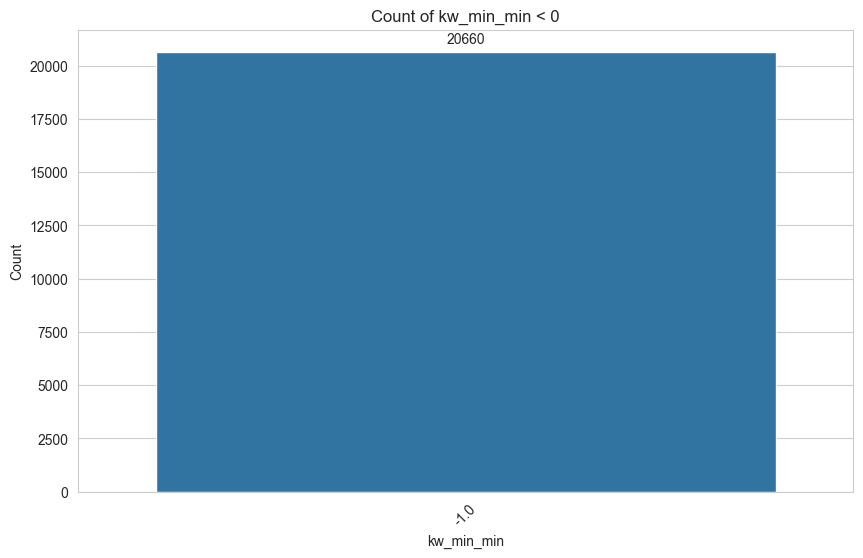

In [453]:
# See what values kw_min_min are < 0
# Set the aesthetic style of the plots
sns.set_style("whitegrid")
df_plot = df[df['kw_min_min'] < 0]
# Bar chart for kw_min_min with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='kw_min_min', data=df_plot)
plt.title('Count of kw_min_min < 0')
plt.xlabel('kw_min_min')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

# all are -1

In [454]:
# Check how many kw_avg_min values are less than 0
(df["kw_avg_min"] < 0).value_counts()

# Substantial amount of kw_avg_min values, need to rectify

kw_avg_min
False    34913
True       767
Name: count, dtype: int64

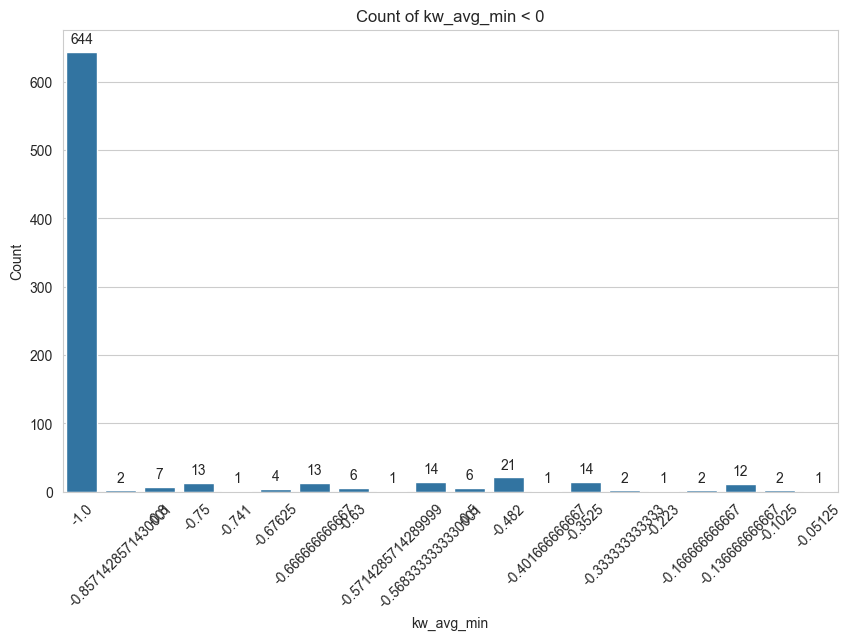

In [455]:
# See what values kw_avg_min are < 0
# Set the aesthetic style of the plots
sns.set_style("whitegrid")
df_plot = df[df['kw_avg_min'] < 0]
# Bar chart for data_channel with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='kw_avg_min', data=df_plot)
plt.title('Count of kw_avg_min < 0')
plt.xlabel('kw_avg_min')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

# many different negative values found for kw_avg_min

In [456]:
# Hypothesise that incorrect negative values of kw_min_min leaked into kw_avg_min
# Check to make sure all negative kw_avg_min has also negative kw_min_min values, should be all 767
neg_avg = df[df["kw_avg_min"] < 0]

# True if every negative kw_avg_min row has kw_min_min == -1
print((neg_avg["kw_min_min"] == -1).all())

# or see the counts
print((neg_avg["kw_min_min"] == -1).value_counts())

# Hypothesis is correct

True
kw_min_min
True    767
Name: count, dtype: int64


In [457]:
# Recification to change all kw_min_min from -1 to 0. However,
# need to check what are kw_max_min values before setting kw_avg_min to 0 as well.
df.loc[df["kw_min_min"] == -1, "kw_max_min"].value_counts()

# Even though some kw_max_min are > 0, impossible to determine the real kw_avg_min values.
# Assume kw_avg_min to be 0 for simplicity, risk low with 767 over 30k+ rows



kw_max_min
1100.0     803
0.0        688
1200.0     496
1300.0     402
1400.0     358
          ... 
82000.0      1
23500.0      1
21400.0      1
10200.0      1
93.0         1
Name: count, Length: 996, dtype: int64

In [ ]:
# Check how many kw_min_avg values are less than 0
(df["kw_min_avg"] < 0).value_counts()

# Very small amount of negative kw_min_avg values, to assume 0

kw_min_avg
False    35674
True         6
Name: count, dtype: int64

In [ ]:
# Modify all negative values to 0

neg_cols = ["kw_min_min", "kw_avg_min", "kw_min_avg"]

df[neg_cols] = df[neg_cols].clip(lower=0)

In [460]:
# Check bounds kw_min_min <= kw_avg_min <= kw_max_min
violations_low  = df[df["kw_min_min"] > df["kw_avg_min"]]
violations_high = df[df["kw_avg_min"] > df["kw_max_min"]]

print(len(violations_low), len(violations_high))
violations_low
violations_high

# No violations

0 0


,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg,kw_min_min_missing


In [461]:
# Plausible for article to not have images or video
# Check entries with no image and no video currently to confirm

cols = ["num_imgs",
        "num_videos"]

df[cols].isnull().sum()

# # Replace null values of num_imgs and num_videos to 0
df[cols] = df[cols].fillna(0)

# # Check to make sure no null values of num_videos
df[cols].isnull().sum()



num_imgs      0
num_videos    0
dtype: int64

In [ ]:
# Check to make sure the following are the same rows with null values
# - Minimum shares of referenced articles in the news website,
# - Maximum shares of referenced articles in the news website,
# - Average shares of referenced articles in the news website

cols = ["self_reference_min_shares",
        "self_reference_max_shares",
        "self_reference_avg_shares"]

nulls = df[cols].isnull()

# Rows where all three are blank
print("All three blank:", nulls.all(axis=1).sum())

# Check entries with no Minimum shares of referenced articles in the news website
(df["self_reference_min_shares"] == 0).sum() 

# Cannot tell true value of self_reference_min_shares, self_reference_max_shares, self_reference_avg_shares from dataset, 
# too coincidental for all 3 to be null at same time, to drop all 721 rows (2% of dataset, low risk)
df = df.dropna(subset=["self_reference_min_shares"]).reset_index(drop=True)

# check no null rows left
df[cols].isnull().sum()

# Null values of self_reference_min_shares, self_reference_max_shares, self_reference_avg_shares appear on the same row

All three blank: 721


self_reference_min_shares    0
self_reference_max_shares    0
self_reference_avg_shares    0
dtype: int64

In [463]:
# check for null rows for:
# Number of links, 
# Number of links to other articles published by the news website
# Possibly removed when self_reference_min_shares dropped because number of rows are the same

cols = ["num_hrefs",
        "num_self_hrefs"]

df[cols].isnull().sum()

num_hrefs         0
num_self_hrefs    0
dtype: int64

In [464]:
# check data_channel value counts
df['data_channel'].value_counts()

# check URL of null data_channel to see if they belong to any of these categories
df.loc[df["data_channel"].isnull(), "URL"]

# Fill null vales with 'other' for now and check how much it affects data via box plot
df["data_channel"] = df["data_channel"].fillna("other")

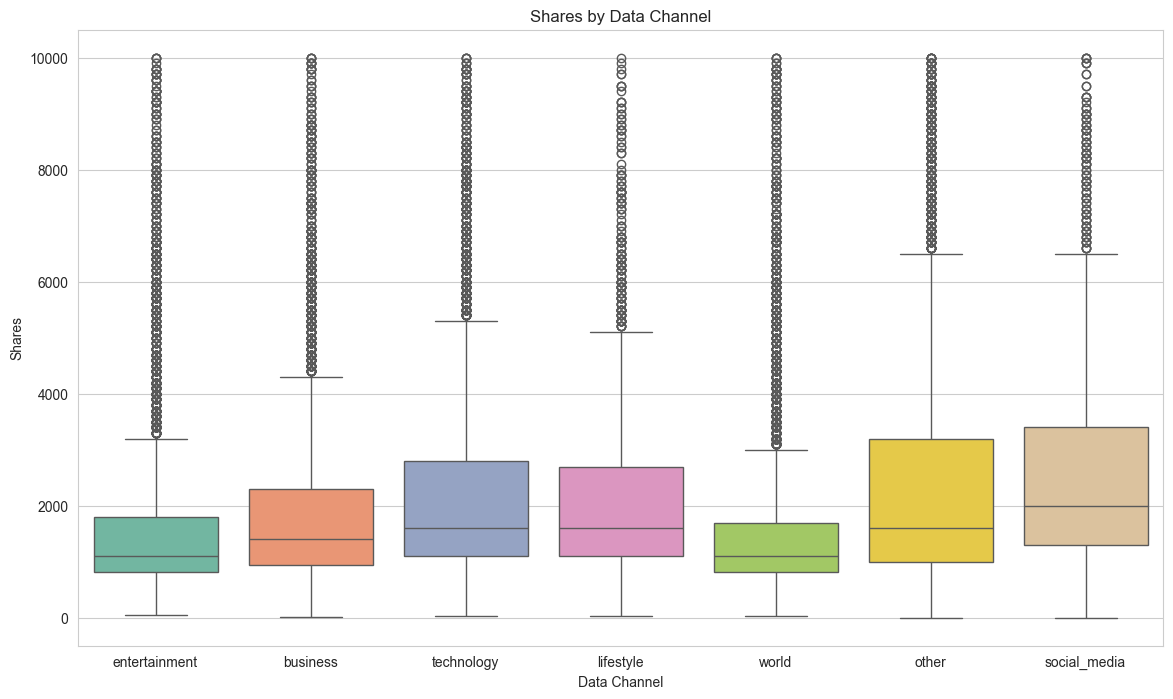

In [465]:
# Remove shares above 10000 to see box plot better
sns.set_style("whitegrid")

df_plot = df[df['shares'] <= 10000]

plt.figure(figsize=(14, 8))
sns.boxplot(x='data_channel', y='shares', data=df_plot, hue='data_channel', palette='Set2')
plt.title('Shares by Data Channel')
plt.xlabel('Data Channel')
plt.ylabel('Shares')
plt.xticks(rotation=0)
plt.show()

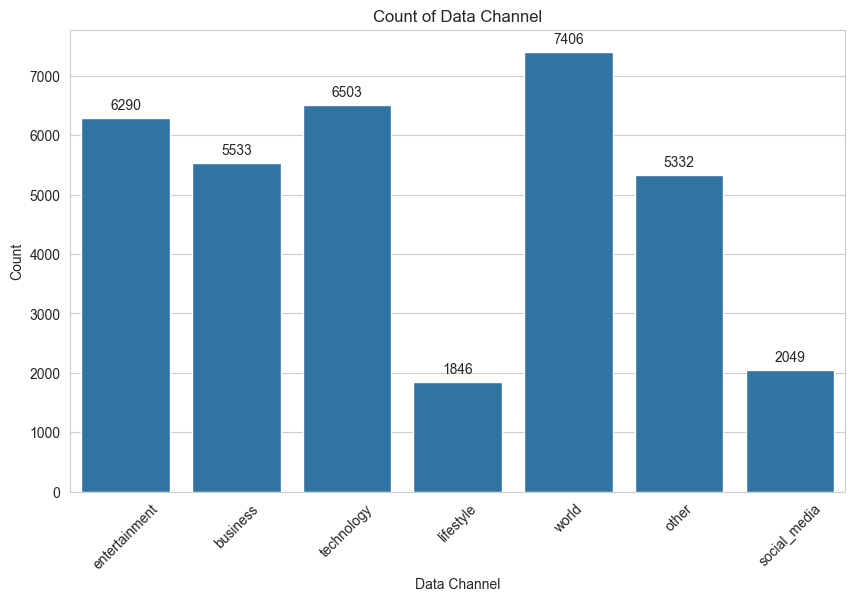

In [466]:
# Check for mode in case impute via mode
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for data_channel with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='data_channel', data=df)
plt.title('Count of Data Channel')
plt.xlabel('Data Channel')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

In [467]:
# Since URL of null data_channel suggest randomness, while box plot and bar chart suggests unwise to impute via mode (world), to drop data_channel with null values
df = df[df["data_channel"] != "other"].reset_index(drop=True)

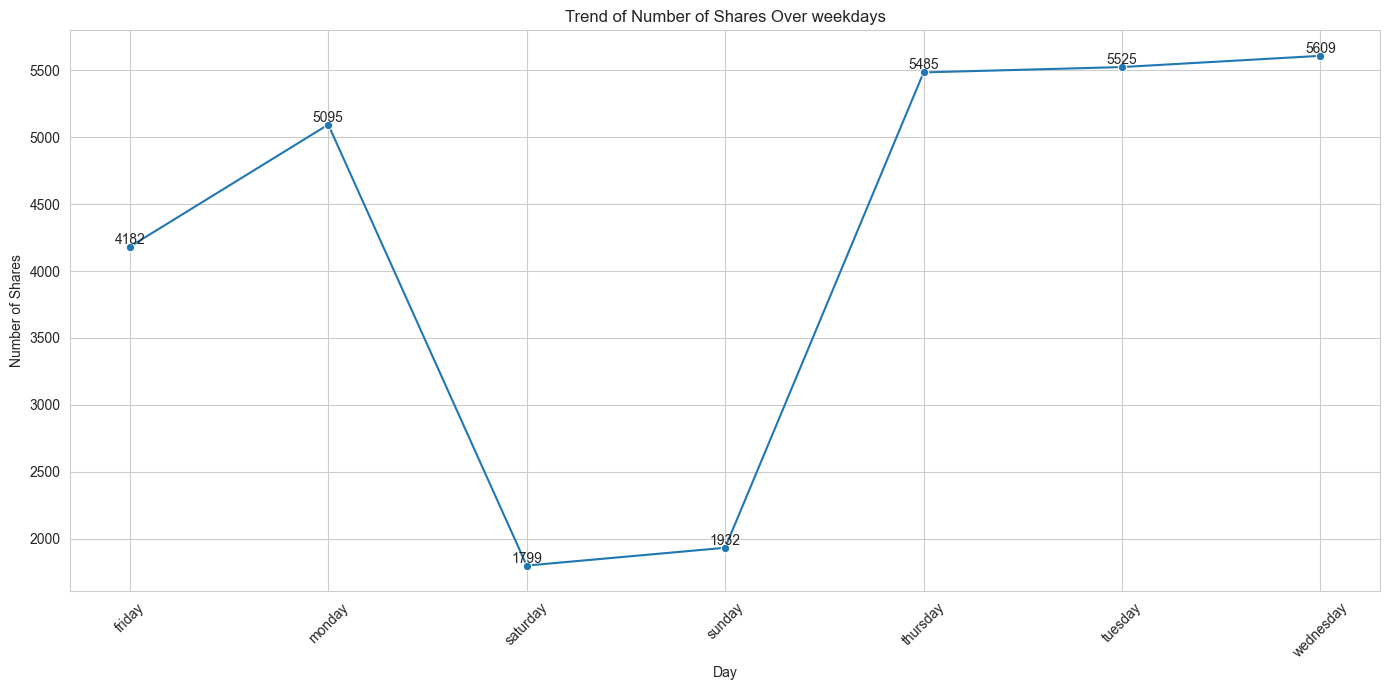

In [468]:
# Curious if days of week affect shares
# Set Aesthetic Style
sns.set_style("whitegrid")

# Count the Number of Shares by Day ofweek
weekday_counts = df['weekday'].value_counts().sort_index()

# Create the Line Chart
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(x=weekday_counts.index, y=weekday_counts.values, marker='o')

# Annotate the Data Points
for x, y in zip(weekday_counts.index, weekday_counts.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom')

# Label the Chart
plt.title('Trend of Number of Shares Over weekdays')
plt.xlabel('Day')
plt.ylabel('Number of Shares')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Significantly more shares on weekdays vs weekends

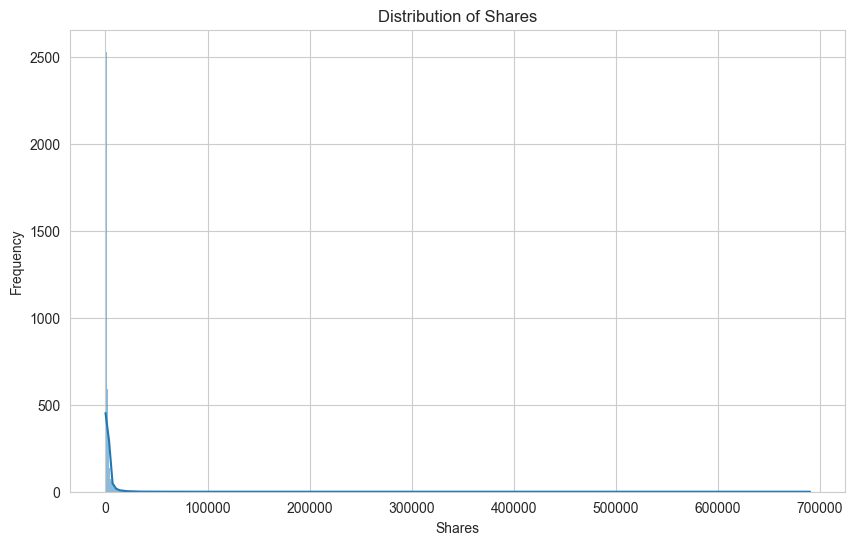

In [469]:
# Check distribution of shares
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for resale price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['shares'], kde=True)  
plt.title('Distribution of Shares')  
plt.xlabel('Shares')  
plt.ylabel('Frequency')  
plt.show()

In [ ]:
# Filter the data for outliers
outliers = df[df['shares'] > 20000]

# Display the outliers
outliers.value_counts()

# Outlier information do not show implausible data 
# Distribution of shares: the gap between the median and mean suggests heavy right skew
# High shares are plausible values, do not manipulate 
# A log transform of the target to be done


ID     URL                                                                      timedelta  weekday    shares  n_tokens_title  n_tokens_content  n_unique_tokens  n_non_stop_words  n_non_stop_unique_tokens  num_hrefs  num_self_hrefs  num_imgs  num_videos  n_comments  average_token_length  data_channel   self_reference_min_shares  self_reference_max_shares  self_reference_avg_shares  num_keywords  kw_min_min  kw_max_min  kw_avg_min  kw_min_max  kw_max_max  kw_avg_max     kw_min_avg   kw_max_avg   kw_avg_avg   kw_min_min_missing
270    http://mashable.com/2013/01/11/deleted-scene-this-is-40-with-megan-fox/  727.0      friday     37400   13.0            140.0             0.786765         1.0               0.935897                  2.0        1.0             0.0       0.0         75.0        4.207143              entertainment  2700.0                     2700.0                     2700.000000                10.0          217.0       1000.0      572.750000  0.0         28000.0     14970.00000

In [471]:
df.isnull().sum()

ID                           0
URL                          0
timedelta                    0
weekday                      0
shares                       0
n_tokens_title               0
n_tokens_content             0
n_unique_tokens              0
n_non_stop_words             0
n_non_stop_unique_tokens     0
num_hrefs                    0
num_self_hrefs               0
num_imgs                     0
num_videos                   0
n_comments                   0
average_token_length         0
data_channel                 0
self_reference_min_shares    0
self_reference_max_shares    0
self_reference_avg_shares    0
num_keywords                 0
kw_min_min                   0
kw_max_min                   0
kw_avg_min                   0
kw_min_max                   0
kw_max_max                   0
kw_avg_max                   0
kw_min_avg                   0
kw_max_avg                   0
kw_avg_avg                   0
kw_min_min_missing           0
dtype: int64

In [472]:
# check for duplicates
df.duplicated().sum()

0

In [473]:
# drop unnecessary columns
df.drop(columns=["ID", "URL"], inplace=True)

## Implementing Pearson Correlation Coefficient

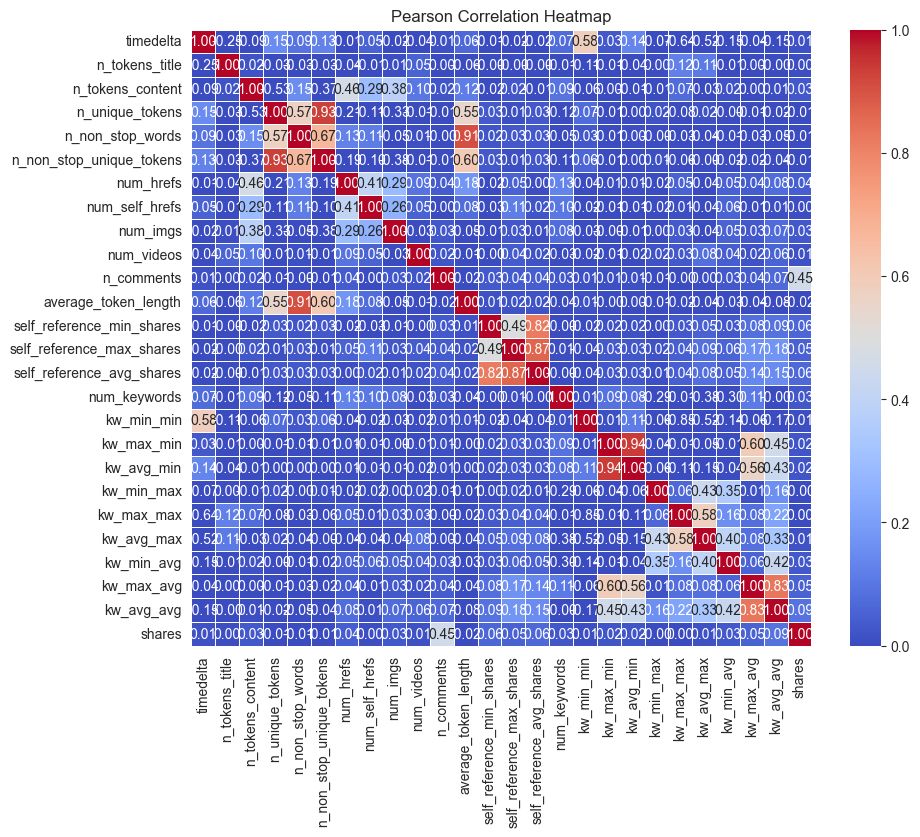

In [475]:
# Select continuous variables  
continuous_vars_all = df[['timedelta', 
                          'n_tokens_title', 
                          'n_tokens_content', 
                          'n_unique_tokens',
                          'n_non_stop_words', 
                          'n_non_stop_unique_tokens',
                          'num_hrefs',
                          'num_self_hrefs', 
                          'num_imgs',  
                          'num_videos',
                          'n_comments', 
                          'average_token_length',
                          'self_reference_min_shares', 
                          'self_reference_max_shares',
                          'self_reference_avg_shares', 
                          'num_keywords',
                          'kw_min_min',
                          'kw_max_min', 
                          'kw_avg_min',
                          'kw_min_max', 
                          'kw_max_max',
                          'kw_avg_max',
                          'kw_min_avg', 
                          'kw_max_avg',
                          'kw_avg_avg', 
                          'shares']]

# Calculate the Pearson correlation matrix for the entire dataset
corr_matrix_pear = continuous_vars_all.corr(method='pearson')

# Plot the heatmap of the correlation matrix for the entire dataset
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_pear, annot=True, cmap='coolwarm', vmin=0, center=0.5, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Pearson Correlation Heatmap')
plt.show()

# n_comments have moderate correlation with shares

## Implementing Spearman Rank Correlation Coefficient

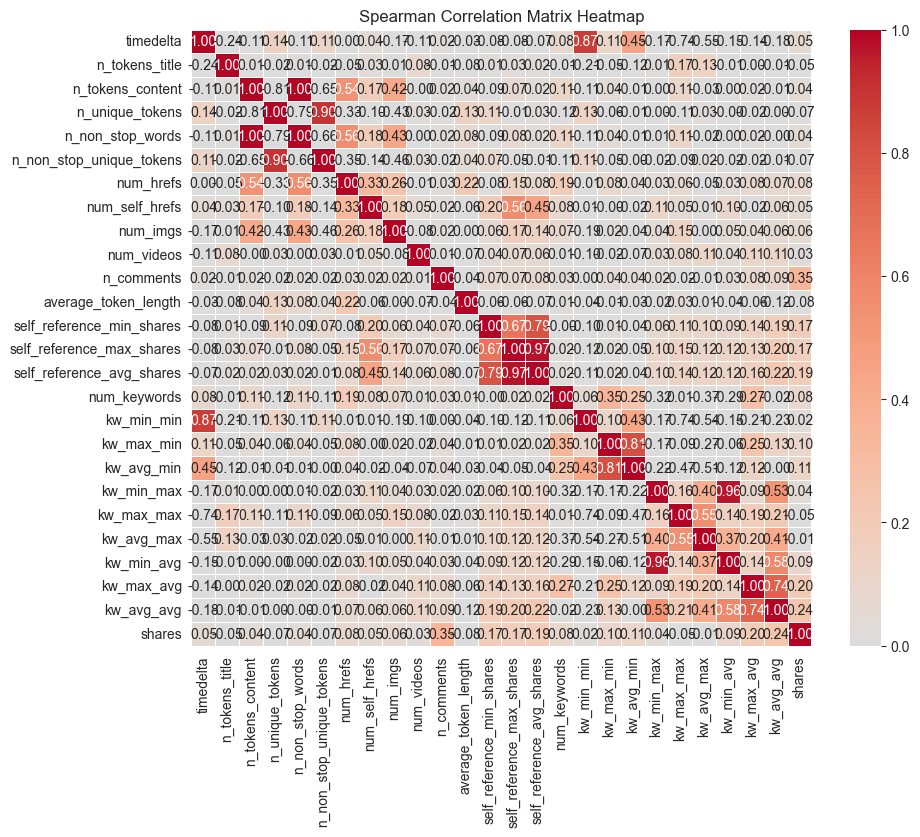

In [ ]:
# Select relevant columns for correlation analysis
spearman_vars = df[['timedelta', 
                          'n_tokens_title', 
                          'n_tokens_content', 
                          'n_unique_tokens',
                          'n_non_stop_words', 
                          'n_non_stop_unique_tokens',
                          'num_hrefs',
                          'num_self_hrefs', 
                          'num_imgs',  
                          'num_videos',
                          'n_comments', 
                          'average_token_length',
                          'self_reference_min_shares', 
                          'self_reference_max_shares',
                          'self_reference_avg_shares', 
                          'num_keywords',
                          'kw_min_min',
                          'kw_max_min', 
                          'kw_avg_min',
                          'kw_min_max', 
                          'kw_max_max',
                          'kw_avg_max',
                          'kw_min_avg', 
                          'kw_max_avg',
                          'kw_avg_avg', 
                          'shares']]

# Compute the Spearman correlation matrix
spearman_corr = spearman_vars.corr(method='spearman')

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0, vmin=0, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()

# n_comments have moderate spearman correlation with shares
# From Pearson and Spearman Correlation, n_comments seem to contribute most to the predictability of the model

## Model implementation

In [ ]:
# Log transform of target feature due to heavy right skew from bar chart above

import numpy as np

X = df.drop(columns='shares')
y = np.log1p(df["shares"])
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (23701, 28) (23701,)
Validation set shape: (2963, 28) (2963,)
Test set shape: (2963, 28) (2963,)


In [478]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define numerical features to be standardized
numerical_features = ['timedelta', 
                        'n_tokens_title', 
                        'n_tokens_content', 
                        'n_unique_tokens',
                        'n_non_stop_words', 
                        'n_non_stop_unique_tokens',
                        'num_hrefs',
                        'num_self_hrefs', 
                        'num_imgs',  
                        'num_videos',
                        'n_comments', 
                        'average_token_length',
                        'self_reference_min_shares', 
                        'self_reference_max_shares',
                        'self_reference_avg_shares', 
                        'num_keywords',
                        'kw_min_min',
                        'kw_max_min', 
                        'kw_avg_min',
                        'kw_min_max', 
                        'kw_max_max',
                        'kw_avg_max',
                        'kw_min_avg', 
                        'kw_max_avg',
                        'kw_avg_avg']

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

In [479]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define nomial features to be one-hot encoded
nominal_features = ['data_channel', 'weekday']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])


In [480]:
from sklearn.compose import ColumnTransformer

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features)
    ],
    n_jobs=1
    )

In [ ]:
from sklearn.linear_model import Ridge

# Create the pipeline with a ridge regression model
ridge_pipeline = Pipeline([("preprocessor", preprocessor),
                 ("regressor", Ridge(alpha=10))])

In [482]:
# Fit the pipeline to the training data
ridge_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = ridge_pipeline.predict(X_val)
y_val_pred

array([7.6899784 , 6.96637106, 7.09313087, ..., 7.08930359, 7.22095279,
       7.78505023])

In [483]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# Calculate regression metrics for validation set
val_mae = mean_absolute_error(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_rmse = root_mean_squared_error(y_val, y_val_pred)  # RMSE is the square root of MSE
val_r2 = r2_score(y_val, y_val_pred)

# Display the metrics
print(f"Validation MAE: {val_mae}")
print(f"Validation MSE: {val_mse}")
print(f"Validation RMSE: {val_rmse}")
print(f"Validation R2: {val_r2}")

Validation MAE: 0.5354367540226326
Validation MSE: 0.5174965967628595
Validation RMSE: 0.7193723630796915
Validation R2: 0.2702306032529097


In [484]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Fit Random Forest Regression 
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                           n_jobs=1, random_state=42))
])
rf_pipeline.fit(X_train, y_train)

# Predict on the validation set with Ridge Regression
y_val_pred_rf = rf_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Ridge Regression
val_mae_rf = mean_absolute_error(y_val, y_val_pred_rf)
val_mse_rf = mean_squared_error(y_val, y_val_pred_rf)
val_rmse_rf = root_mean_squared_error(y_val, y_val_pred_rf)  # RMSE is the square root of MSE
val_r2_rf = r2_score(y_val, y_val_pred_rf)

# Display the metrics for Ridge Regression
print("Random Forest Regression Metrics:")
print(f"Random Forest Validation MAE: {val_mae_rf}")
print(f"Random Forest Validation MSE: {val_mse_rf}")
print(f"Random Forest Validation RMSE: {val_rmse_rf}")
print(f"Random Forest Validation R²: {val_r2_rf}")

Random Forest Regression Metrics:
Random Forest Validation MAE: 0.4579471219493483
Random Forest Validation MSE: 0.42175865408137486
Random Forest Validation RMSE: 0.6494294835325656
Random Forest Validation R²: 0.4052394537719608


In [ ]:
# Fit Gradient Boosting
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(random_state=42))
])
gb_pipeline.fit(X_train, y_train)

# Predict on the validation set with Lasso Regression
y_val_pred_gb = gb_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Lasso Regression
val_mae_gb = mean_absolute_error(y_val, y_val_pred_gb)
val_mse_gb = mean_squared_error(y_val, y_val_pred_gb)
val_rmse_gb = root_mean_squared_error(y_val, y_val_pred_gb)  # RMSE is the square root of MSE
val_r2_gb = r2_score(y_val, y_val_pred_gb)

# Display the metrics for Lasso Regression
print("Gradient Boosting Metrics:")
print(f"Gradient Boosting Validation MAE: {val_mae_gb}")
print(f"Gradient Boosting Validation MSE: {val_mse_gb}")
print(f"Gradient Boosting Validation RMSE: {val_rmse_gb}")
print(f"Gradient Boosting Validation R²: {val_r2_gb}")

Gradient Boosting Metrics:
Gradient Boosting Validation MAE: 0.4544195042474086
Gradient Boosting Validation MSE: 0.41133935897684426
Gradient Boosting Validation RMSE: 0.6413574346468935
Gradient Boosting Validation R²: 0.4199326570713201


In [486]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

ridge_param_grid = {
    'regressor__alpha': [0.1, 1, 10, 100, 1000],
    'regressor__fit_intercept': [True, False]
}

rf_param_grid = {
    'regressor__max_depth': [8, 12, 16, None],
    'regressor__min_samples_leaf': [3, 5, 10, 20],
}

gb_param_grid = {
    'regressor__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'regressor__max_depth': [3, 5, 7, None],
    'regressor__max_iter': [200, 400, 600, 800],
    'regressor__min_samples_leaf': [20, 50, 100, 200],
}

model_configs = {
    'Ridge': (Ridge(), ridge_param_grid, None),
    'Random Forest': (RandomForestRegressor(n_estimators=200, n_jobs=1, random_state=42),
                      rf_param_grid, 15),
    'Gradient Boosting': (HistGradientBoostingRegressor(random_state=42),
                          gb_param_grid, 25),
}

searches = {}
for name, (model, grid, n_iter) in model_configs.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])

    if n_iter is None:
        search = GridSearchCV(pipe, grid, cv=5, scoring='r2', n_jobs=1)
    else:
        search = RandomizedSearchCV(pipe, grid, n_iter=n_iter, cv=5,
                                    scoring='r2', random_state=42, n_jobs=1)

    search.fit(X_train, y_train)          # y_train is log1p(shares)
    searches[name] = search

    print(f"{name}: best CV R2 = {search.best_score_:.3f}")
    print(f"   best params: {search.best_params_}")

Ridge: best CV R2 = 0.254
   best params: {'regressor__alpha': 100, 'regressor__fit_intercept': True}
Random Forest: best CV R2 = 0.436
   best params: {'regressor__min_samples_leaf': 5, 'regressor__max_depth': None}
Gradient Boosting: best CV R2 = 0.449
   best params: {'regressor__min_samples_leaf': 20, 'regressor__max_iter': 600, 'regressor__max_depth': None, 'regressor__learning_rate': 0.03}


In [488]:
for name, search in searches.items():
    y_val_pred = search.best_estimator_.predict(X_val)

# report best model evaluation on validation set
val_mae = mean_absolute_error(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_rmse = root_mean_squared_error(y_val, y_val_pred)  # RMSE is the square root of MSE
val_r2 = r2_score(y_val, y_val_pred)

print("Best Regression Metrics:")
print(f"Validation MAE: {val_mae}")
print(f"Validation MSE: {val_mse}")
print(f"Validation RMSE: {val_rmse}")
print(f"Validation R²: {val_r2}")


Best Regression Metrics:
Validation MAE: 0.4546486571554518
Validation MSE: 0.41137423564590875
Validation RMSE: 0.6413846237990967
Validation R²: 0.4198834742826738


In [489]:
# report best model evaluation on test set
y_test_pred = search.best_estimator_.predict(X_test)

# Calculate regression metrics for the test set for Ridge
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Best Ridge Regression Model, Final Test Metrics:")
print(f"Final Test MAE: {test_mae}")
print(f"Final Test MSE: {test_mse}")
print(f"Final Test RMSE: {test_rmse}")
print(f"Final Test R²: {test_r2}")

Best Ridge Regression Model, Final Test Metrics:
Final Test MAE: 0.46038403531714467
Final Test MSE: 0.4195088044024067
Final Test RMSE: 0.6476949933436313
Final Test R²: 0.44276502957618746
